!pip install pandas numpy opendatasets scikit-learn matplotlib

In [6]:
!pip install pandas numpy opendatasets scikit-learn matplotlib
!pip install legacy-cgi
import os
import glob
import warnings
warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import opendatasets as od

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, log_loss, brier_score_loss, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.8/230.8 kB 54.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.2/78.2 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.7/66.7 kB 10.9 MB/s eta 0:00:00


In [7]:

df = pd.read_csv("heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


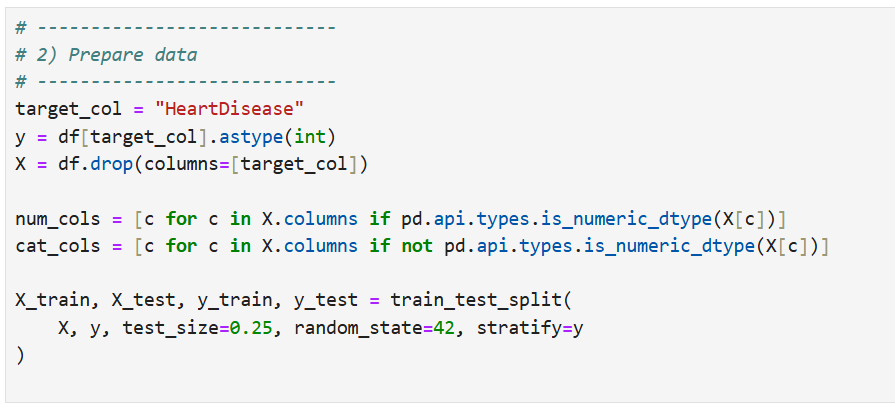

In [8]:
target_col = "HeartDisease"
y = df[target_col].astype(int)
X = df.drop(columns=[target_col])

num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

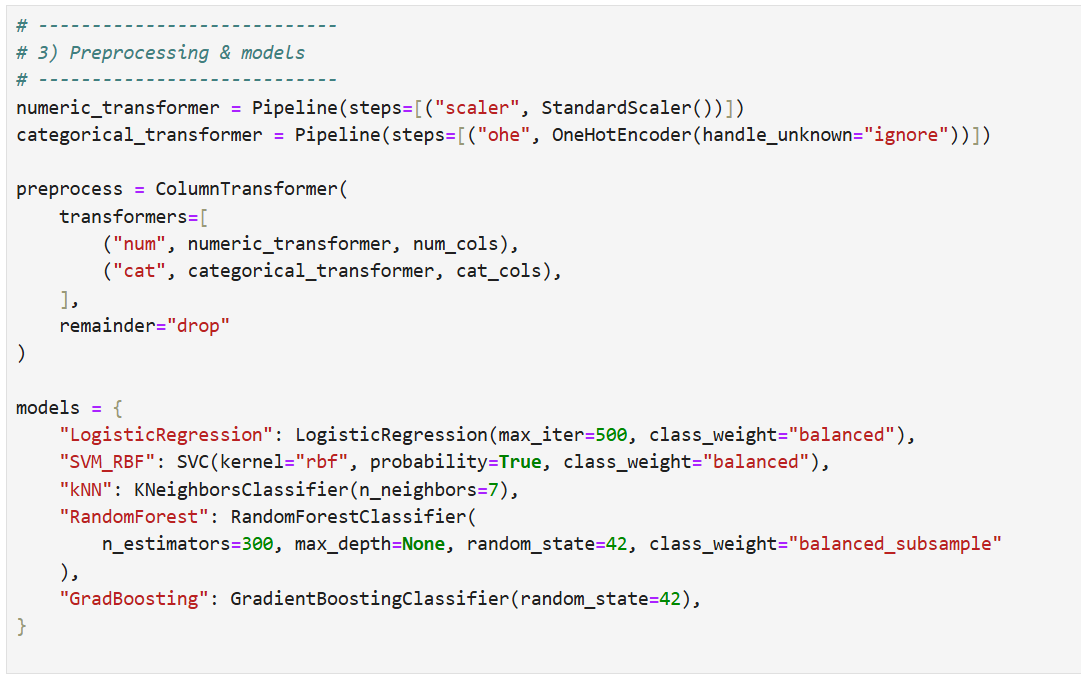



In [9]:
numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[("ohe", OneHotEncoder(handle_unknown="ignore"))])

preprocess = ColumnTransformer(
    transformers = [
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop"
)

models = {
    "LogisticRegression": LogisticRegression(max_iter=500, class_weight="balanced"),
    "SVM_RBF": SVC(kernel="rbf", probability=True, class_weight="balanced"), 
    "kNN": KNeighborsClassifier(n_neighbors=7),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, max_depth=None, random_state=42, class_weight="balanced_subsample"
    ),
    "GradBoosting": GradientBoostingClassifier(random_state=42),
}

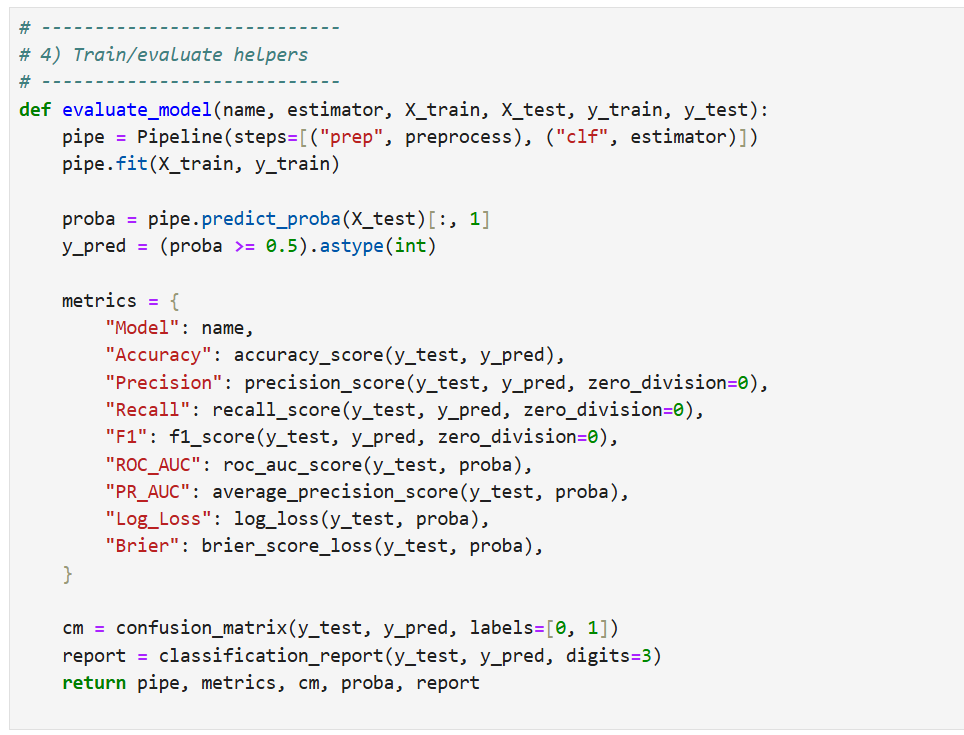

In [18]:
def evaluate_model(name, estimator, X_train, X_test, y_train, y_test):
    pipe = Pipeline(steps=[("prep", preprocess), ("clf", estimator)])
    pipe.fit(X_train, y_train)

    proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = (proba >= 0.5).astype(int)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "PR_AUC": roc_auc_score(y_test, proba),
        "Log_Loss": log_loss(y_test, proba), 
        "Brier": brier_score_loss(y_test, proba),
    }

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    report = classification_report(y_test, y_pred, digits=3)
    return pipe, metrics, cm, proba, report

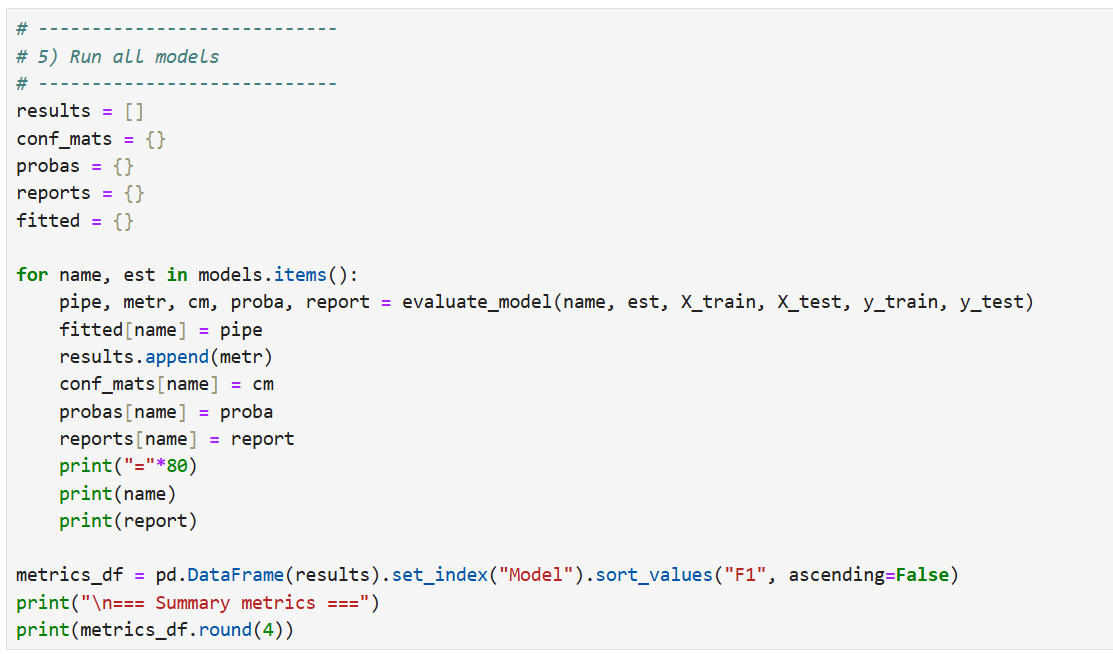

In [20]:
results = []
conf_mats = {}
probas = {}
reports = {}
fitted = {}

for name, est in models.items():
    pipe, metr, cm, proba, report = evaluate_model(name, est, X_train, X_test, y_train, y_test)
    fitted[name] = pipe
    results.append(metr)
    conf_mats[name] = cm
    probas[name] = proba
    reports[name] = report
    print("="*80)
    print(name)
    print(report)

metrics_df = pd.DataFrame(results).set_index("Model").sort_values("F1", ascending=False)
print("\n=== Summary Metrics ===")
print(metrics_df.round(4))

LogisticRegression
              precision    recall  f1-score   support

           0      0.882     0.874     0.878       103
           1      0.898     0.906     0.902       127

    accuracy                          0.891       230
   macro avg      0.890     0.890     0.890       230
weighted avg      0.891     0.891     0.891       230

SVM_RBF
              precision    recall  f1-score   support

           0      0.907     0.854     0.880       103
           1      0.887     0.929     0.908       127

    accuracy                          0.896       230
   macro avg      0.897     0.892     0.894       230
weighted avg      0.896     0.896     0.895       230

kNN
              precision    recall  f1-score   support

           0      0.908     0.864     0.886       103
           1      0.894     0.929     0.911       127

    accuracy                          0.900       230
   macro avg      0.901     0.897     0.898       230
weighted avg      0.900     0.900     0.900

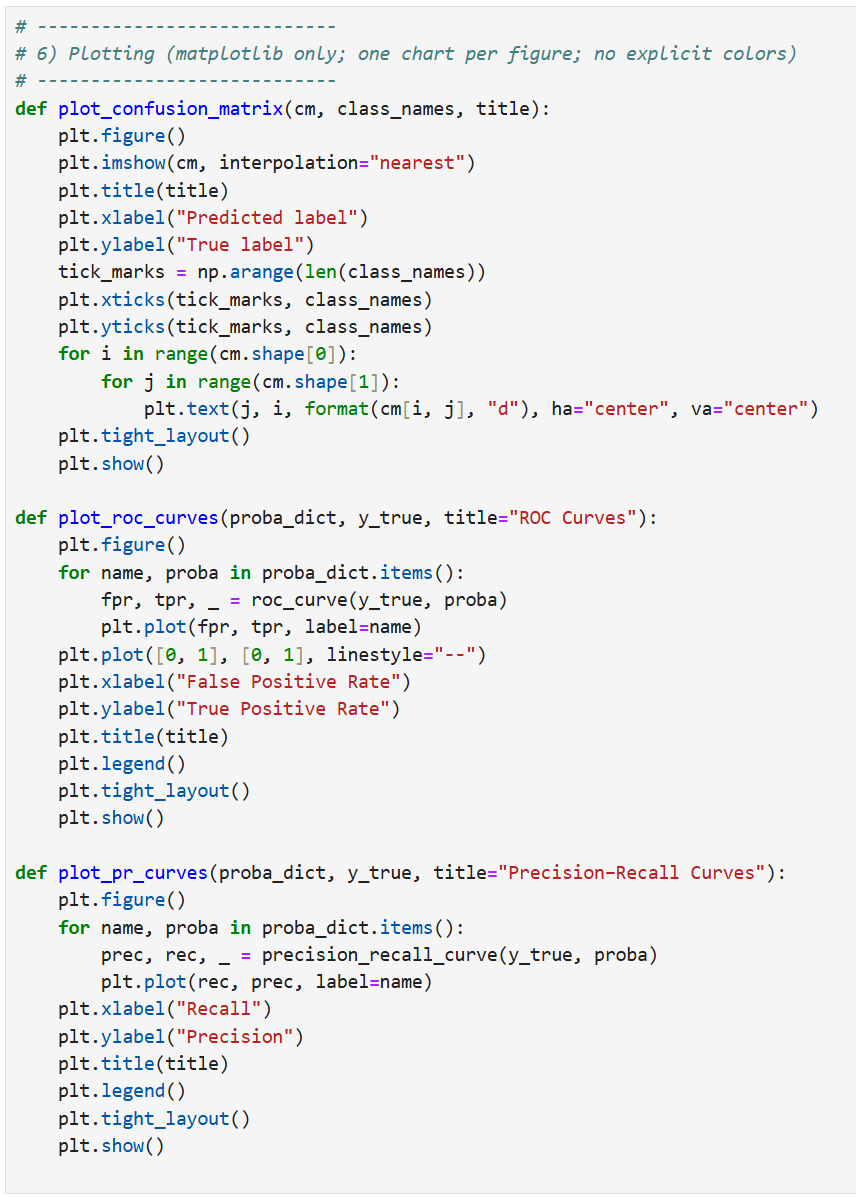

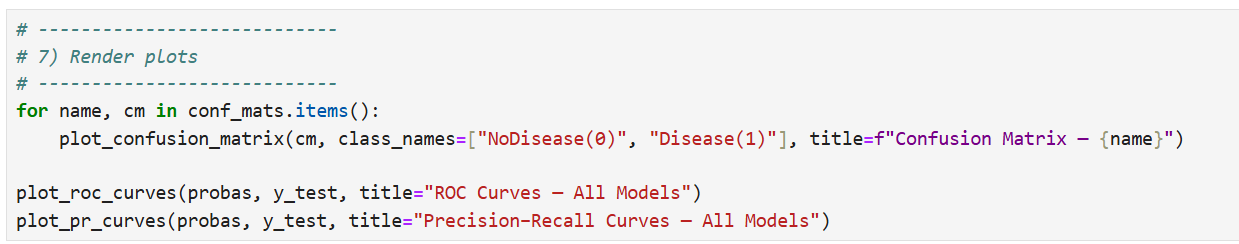